<a href="https://colab.research.google.com/github/VizDataWorks/CapitalOne_DataAnalysis/blob/main/ecommerce-challenge/notebooks/05_best_customer_base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05 · Future next steps: our best customer base, and KPIs to grow it

**Question:** Where is our best customer base, and what are some KPIs the company should track to acquire more customers there?

**Short answer:** **Our best customers are Tech Enthusiasts, and their value comes from buying electronics.** They are 12.6% of customers but bring 30.8% of profit: $404 per customer, against $120–150 for every other segment. Geography matters much less. Most of them are in the Pacific West (Oregon, Nevada, California, Washington), while the most valuable per customer are in the East (New Jersey, Georgia). To win more of them, track acquisition cost against their value, how fast new customers start ordering, how many move up to Frequent or VIP, and whether electronics stay in stock.

**Approach**
- **Value = profit per customer over 2024–2025**, using the same order rules as notebooks 03 and 04: item profit − Black Friday and referral discounts + shipping charged − $4.99 carrier fee. Delivered orders only.
- **Every customer counts**, including those with no orders (profit $0), so averages show what a typical customer in each group is worth.
- **Orders from buyers who aren't in the customer table are left out**, since they have no segment or location.

## 1. Setup

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Get the project data from GitHub: no Google Drive or sign-in needed
REPO = "https://github.com/VizDataWorks/CapitalOne_DataAnalysis.git"
!rm -rf repo
!git clone -q --depth 1 {REPO} repo

CLEAN = os.path.join("repo", "ecommerce-challenge", "data", "clean")
pd.set_option("display.max_columns", 30, "display.width", 160)

# Business rules from the brief
REFERRAL_DISCOUNT = 0.10
BLACK_FRIDAY_DISCOUNT = 0.20
BLACK_FRIDAYS = pd.to_datetime(["2024-11-29", "2025-11-28"])
CARRIER_FEE = 4.99


def shipping_charged(item_total):
    # $7.99 under $50, $4.99 from $50 to $99.99, free from $100
    return np.select([item_total < 50, item_total < 100], [7.99, 4.99], 0.0)

## 2. Load data

In [2]:
customers = pd.read_csv(os.path.join(CLEAN, "customers.csv"), dtype=str)
products = pd.read_csv(os.path.join(CLEAN, "products.csv"), dtype={"sku_id": str})
sales = pd.read_csv(os.path.join(CLEAN, "sales.csv.gz"), dtype=str)

# CSV files store everything as text: restore the types we need
customers["is_referred"] = pd.to_numeric(customers.is_referred).astype("Int64")
customers["signup_year"] = pd.to_datetime(customers.signup_date).dt.year.astype("Int64")
for c in ["currently_active_vendor", "active_product"]:
    products[c] = products[c].astype(str).eq("True")
sales["quantity"] = pd.to_numeric(sales.quantity)
sales["is_revenue"] = sales.is_revenue.eq("True")
sales["order_datetime"] = pd.to_datetime(sales.order_datetime)

## 3. Build one row per delivered order

Same rules as notebooks 03 and 04.

In [3]:
# Delivered lines with a valid quantity, with product details attached
lines = sales[sales.is_revenue & sales.quantity.notna()].merge(
    products[["sku_id", "category_name", "price", "profit_margin", "currently_active_vendor", "active_product"]],
    on="sku_id", how="left")
assert lines.price.notna().all(), "some sales lines have no matching product"
lines["list_revenue"] = lines.quantity * lines.price
lines["item_profit"] = lines.list_revenue * lines.profit_margin

# One row per order
orders = lines.groupby("order_id").agg(
    buyer_id=("buyer_id", "first"),
    order_time=("order_datetime", "min"),
    list_revenue=("list_revenue", "sum"),
    item_profit=("item_profit", "sum"),
).reset_index()

# Discounts: Black Friday first, then 10% off a referred buyer's first order
orders["is_black_friday"] = orders.order_time.dt.normalize().isin(BLACK_FRIDAYS)
orders["black_friday_discount"] = np.where(orders.is_black_friday, orders.list_revenue * BLACK_FRIDAY_DISCOUNT, 0.0)
orders["pre_referral_total"] = orders.list_revenue - orders.black_friday_discount
orders = orders.sort_values(["order_time", "order_id"])
has_buyer = orders.buyer_id.notna() & orders.order_time.notna()
orders["order_rank"] = orders[has_buyer].groupby("buyer_id").cumcount() + 1
orders = orders.merge(customers[["buyer_id", "is_referred"]], on="buyer_id", how="left")
is_referral_order = orders.order_rank.eq(1) & orders.is_referred.eq(1).fillna(False)
orders["referral_discount"] = np.where(is_referral_order, orders.pre_referral_total * REFERRAL_DISCOUNT, 0.0)

# Revenue, shipping and profit
orders["item_revenue"] = orders.pre_referral_total - orders.referral_discount
orders["shipping"] = shipping_charged(orders.item_revenue)
orders["profit"] = (orders.item_profit - orders.black_friday_discount - orders.referral_discount
                    + orders.shipping - CARRIER_FEE)

In [5]:
# One row per customer: orders and profit in 2024–2025 (0 for customers with no orders)
per_buyer = orders.dropna(subset=["buyer_id"]).groupby("buyer_id").agg(
    orders=("order_id", "size"), profit=("profit", "sum"), revenue=("item_revenue", "sum"))
cust = customers.merge(per_buyer, on="buyer_id", how="left")
cust[["orders", "profit", "revenue"]] = cust[["orders", "profit", "revenue"]].fillna(0)
cust["is_active"] = cust.orders > 0

total_profit = cust.profit.sum()
print(f"{len(cust):,} customers, {cust.is_active.mean():.1%} active in 2024–2025, "
      f"${total_profit:,.0f} profit from customers in the customer table")

47,500 customers, 50.1% active in 2024–2025, $7,859,163 profit from customers in the customer table


## 4. What separates high-value customers

Profit per customer for each customer attribute. A wide spread means the attribute matters.

In [6]:
factors = {
    "Customer group": "customer_group",
    "Segment": "customer_segment",
    "Region": "region",
    "Sales channel": "preferred_channel",
    "Payment method": "preferred_payment",
    "Signup year": "signup_year",
}

rows = []
for label, col in factors.items():
    g = cust.groupby(col).profit.mean()
    rows.append({
        "factor": label,
        "lowest": g.min(), "highest": g.max(), "spread": g.max() - g.min(),
        "by group": " · ".join(f"{k} ${v:,.0f}" for k, v in g.sort_values(ascending=False).items()),
    })
spread = pd.DataFrame(rows).set_index("factor").sort_values("spread", ascending=False)
with pd.option_context("display.max_colwidth", 200):
    display(spread.style.format({"lowest": "${:,.0f}", "highest": "${:,.0f}", "spread": "${:,.0f}"}))

,lowest,highest,spread,by group
factor,,,,
Customer group,$0,"$1,687","$1,687","VIP $1,687 · Frequent $544 · Regular $176 · Occasional $95 · Dormant $0"
Segment,$120,$404,$284,Tech Enthusiast $404 · Young Parent $150 · Beauty Lover $146 · Home Organizer $130 · Cozy Homemaker $125 · Fashion Shopper $124 · Fitness Buff $123 · Bargain Hunter $120
Payment method,$156,$170,$14,Other $170 · Credit Card $168 · Digital Wallet $165 · Debit Card $156
Signup year,$162,$171,$9,2020 $171 · 2019 $168 · 2023 $166 · 2018 $165 · 2021 $163 · 2022 $162
Region,$163,$169,$5,East $169 · Central $165 · West $164 · Other $163
Sales channel,$165,$166,$1,Mobile $166 · App $165 · Website $165


In [7]:
# Profit concentration: VIP + Frequent customers
top_tier = cust.customer_group.isin(["VIP", "Frequent"])
print(f"VIP + Frequent: {top_tier.mean():.1%} of customers, {cust.profit[top_tier].sum() / total_profit:.1%} of profit")
print("Share of each segment that is VIP or Frequent: "
      f"{cust.groupby('customer_segment').apply(lambda d: d.customer_group.isin(['VIP', 'Frequent']).mean()).min():.1%} to "
      f"{cust.groupby('customer_segment').apply(lambda d: d.customer_group.isin(['VIP', 'Frequent']).mean()).max():.1%}")
print(f"Customers with no orders in 2024–2025: {(~cust.is_active).mean():.1%}")

VIP + Frequent: 15.0% of customers, 70.1% of profit
Share of each segment that is VIP or Frequent: 14.6% to 15.3%
Customers with no orders in 2024–2025: 49.9%


/tmp/ipykernel_1137/686119271.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  f"{cust.groupby('customer_segment').apply(lambda d: d.customer_group.isin(['VIP', 'Frequent']).mean()).min():.1%} to "
/tmp/ipykernel_1137/686119271.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  f"{cust.groupby('customer_segment').apply(lambda d: d.customer_group.isin(['VIP', 'Frequent']).mean()).max():.1%}")


## 5. Segments: who is most valuable, and why

In [8]:
# Category mix: electronics share of each segment's spend
line_seg = lines.merge(customers[["buyer_id", "customer_segment"]], on="buyer_id", how="inner")
elec_share = (line_seg.assign(elec=line_seg.list_revenue.where(line_seg.category_name.eq("Electronics"), 0))
                      .groupby("customer_segment")[["elec", "list_revenue"]].sum())
elec_share = elec_share.elec / elec_share.list_revenue

orders_seg = orders.merge(customers[["buyer_id", "customer_segment"]], on="buyer_id", how="inner")
segments = cust.groupby("customer_segment").agg(
    customers=("buyer_id", "size"),
    profit=("profit", "sum"),
    profit_per_customer=("profit", "mean"),
    active_pct=("is_active", "mean"),
)
segments["share_of_customers"] = segments.customers / segments.customers.sum()
segments["share_of_profit"] = segments.profit / total_profit
segments["orders_per_active_customer"] = cust[cust.is_active].groupby("customer_segment").orders.mean()
segments["profit_per_order"] = orders_seg.groupby("customer_segment").profit.mean()
segments["electronics_share_of_spend"] = elec_share
segments = segments.drop(columns="profit").sort_values("profit_per_customer", ascending=False)
segments.index.name = "Segment"

segments.style.format({
    "customers": "{:,}", "profit_per_customer": "${:,.0f}", "active_pct": "{:.1%}",
    "share_of_customers": "{:.1%}", "share_of_profit": "{:.1%}", "orders_per_active_customer": "{:.2f}",
    "profit_per_order": "${:.2f}", "electronics_share_of_spend": "{:.0%}"})

,customers,profit_per_customer,active_pct,share_of_customers,share_of_profit,orders_per_active_customer,profit_per_order,electronics_share_of_spend
Segment,,,,,,,,
Tech Enthusiast,"5,986",$404,50.3%,12.6%,30.8%,9.69,$82.89,87%
Young Parent,"5,864",$150,49.4%,12.3%,11.2%,9.37,$32.38,29%
Beauty Lover,"5,947",$146,50.5%,12.5%,11.0%,9.27,$31.08,25%
Home Organizer,"5,919",$130,50.9%,12.5%,9.8%,9.28,$27.59,30%
Cozy Homemaker,"5,987",$125,49.9%,12.6%,9.5%,9.39,$26.70,28%
Fashion Shopper,"5,912",$124,49.5%,12.4%,9.3%,9.55,$26.16,20%
Fitness Buff,"5,882",$123,49.6%,12.4%,9.2%,9.30,$26.58,28%
Bargain Hunter,"6,003",$120,50.3%,12.6%,9.2%,9.33,$25.55,27%


In [10]:
tech = line_seg.customer_segment.eq("Tech Enthusiast")
other_elec = (line_seg.list_revenue.where(line_seg.category_name.eq("Electronics"), 0)[~tech].sum()
              / line_seg.list_revenue[~tech].sum())
print(f"Electronics share of spend: Tech Enthusiasts {elec_share['Tech Enthusiast']:.0%}, everyone else {other_elec:.0%}")

Electronics share of spend: Tech Enthusiasts 87%, everyone else 27%


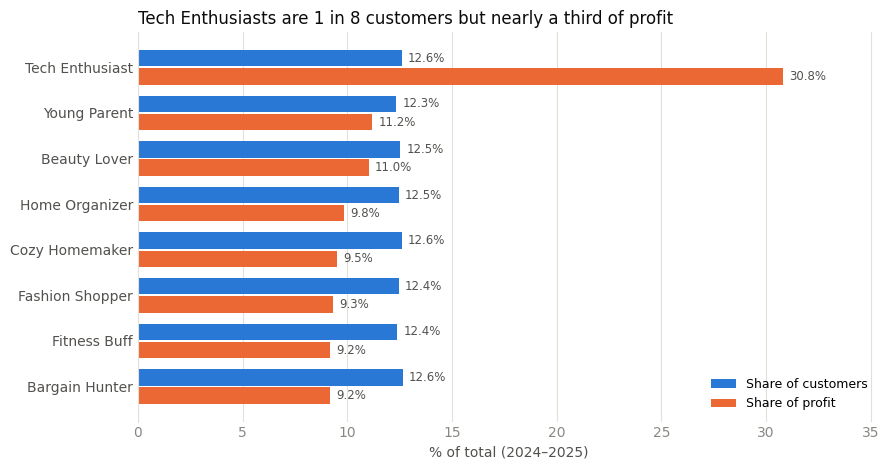

In [11]:
# Chart: share of customers vs share of profit, by segment
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#52514e", "#898781", "#e1e0d9"

d = segments[["share_of_customers", "share_of_profit"]].sort_values("share_of_profit")
y = np.arange(len(d))
h = 0.36
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(y + h / 2 + 0.02, d.share_of_customers * 100, height=h, color=BLUE, label="Share of customers", zorder=2)
ax.barh(y - h / 2 - 0.02, d.share_of_profit * 100, height=h, color=ORANGE, label="Share of profit", zorder=2)
for yy, v in zip(y, d.share_of_customers * 100):
    ax.text(v + 0.3, yy + h / 2 + 0.02, f"{v:.1f}%", va="center", fontsize=8.5, color=INK)
for yy, v in zip(y, d.share_of_profit * 100):
    ax.text(v + 0.3, yy - h / 2 - 0.02, f"{v:.1f}%", va="center", fontsize=8.5, color=INK)
ax.set_yticks(y)
ax.set_yticklabels(d.index)
ax.set_title("Tech Enthusiasts are 1 in 8 customers but nearly a third of profit", loc="left",
             fontsize=12, color="#0b0b0b")
ax.set_xlabel("% of total (2024–2025)", color=INK)
ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=0)
ax.tick_params(colors=MUTED, length=0)
ax.tick_params(axis="y", colors=INK)
for s in ["top", "right", "bottom"]:
    ax.spines[s].set_visible(False)
ax.spines["left"].set_color(GRID)
ax.set_xlim(0, d.values.max() * 100 * 1.15)
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

## 6. Where the Tech Enthusiasts are

In [ ]:
te = cust[cust.customer_segment.eq("Tech Enthusiast")]

by_state = te.groupby(["region", "state"]).agg(
    customers=("buyer_id", "size"), profit_per_customer=("profit", "mean"), total_profit=("profit", "sum"))
by_state = by_state.sort_values("total_profit", ascending=False).reset_index(level="region")
by_state.index.name = "State"
display(by_state.head(10).style.format(
    {"customers": "{:,}", "profit_per_customer": "${:,.0f}", "total_profit": "${:,.0f}"}))

by_region = te.groupby("region").agg(
    customers=("buyer_id", "size"), profit_per_customer=("profit", "mean"), total_profit=("profit", "sum"))
by_region["share_of_te_customers"] = by_region.customers / by_region.customers.sum()
by_region["share_of_te_profit"] = by_region.total_profit / by_region.total_profit.sum()
by_region = by_region.sort_values("total_profit", ascending=False)
by_region.index.name = "Region"
by_region.style.format({"customers": "{:,}", "profit_per_customer": "${:,.0f}", "total_profit": "${:,.0f}",
                        "share_of_te_customers": "{:.1%}", "share_of_te_profit": "{:.1%}"})

,region,customers,profit_per_customer,total_profit
State,,,,
OR,West,617,$492,"$303,447"
NV,West,610,$400,"$243,861"
CA,West,562,$338,"$190,165"
WA,West,604,$305,"$184,069"
NJ,East,285,$527,"$150,325"
GA,East,284,$510,"$144,777"
PA,East,308,$432,"$133,105"
VA,East,300,$415,"$124,385"
NY,East,314,$396,"$124,201"


,customers,profit_per_customer,total_profit,share_of_te_customers,share_of_te_profit
Region,,,,,
West,"2,393",$385,"$921,542",40.0%,38.1%
East,"1,805",$438,"$790,883",30.2%,32.7%
Central,"1,191",$386,"$459,497",19.9%,19.0%
Other,597,$416,"$248,078",10.0%,10.3%


## 7. Supply risk for the best customers

Tech Enthusiasts mostly buy electronics. How much electronics revenue comes from products the company can't currently source (vendor or product inactive), and how much stock is there?

In [ ]:
lines["can_source"] = lines.currently_active_vendor & lines.active_product
products["can_source"] = products.currently_active_vendor & products.active_product

supply = pd.DataFrame({
    "revenue_not_sourceable": lines.groupby("category_name").apply(
        lambda d: d.list_revenue[~d.can_source].sum() / d.list_revenue.sum()),
    "products": products.groupby("category_name").size(),
    "stock_per_product": products.groupby("category_name").current_stock.mean(),
}).sort_values("revenue_not_sourceable", ascending=False)
supply.index.name = "Category"

other_stock = products.loc[products.category_name.ne("Electronics"), "current_stock"].mean()
print(f"Stock per product: Electronics {supply.loc['Electronics', 'stock_per_product']:.0f}, "
      f"other categories {other_stock:.0f}")
supply.style.format({"revenue_not_sourceable": "{:.1%}", "stock_per_product": "{:.0f}"})

Stock per product: Electronics 40, other categories 66


/tmp/ipykernel_1524/1541668195.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "revenue_not_sourceable": lines.groupby("category_name").apply(


,revenue_not_sourceable,products,stock_per_product
Category,,,
Sports & Outdoors,100.0%,116,54
Beauty,49.9%,182,80
Electronics,46.5%,87,40
Books,42.3%,104,74
Toys & Games,38.7%,151,58
Home & Kitchen,38.1%,155,54
Clothing,33.4%,180,69
Pet Supplies,18.3%,62,76


## 8. Inputs for the KPI targets

In [ ]:
# Signups per year
signups = customers.signup_year.value_counts().sort_index()
display(signups.rename("new customers").to_frame().T)

# A CAC ceiling that keeps two-year profit at least 3× acquisition cost
te_value = segments.loc["Tech Enthusiast", "profit_per_customer"]
print(f"Two-year profit per Tech Enthusiast: ${te_value:,.0f} -> CAC ceiling at LTV:CAC = 3: ${te_value / 3:,.0f}")

signup_year,2018,2019,2020,2021,2022,2023
new customers,3459,3777,6255,7013,8538,17978


Two-year profit per Tech Enthusiast: $404 -> CAC ceiling at LTV:CAC = 3: $135


## 9. Conclusion and KPIs

### Where the best customer base is

- **Customer group separates value the most:** VIP $1,687 per customer, Frequent $544, Regular $176, Occasional $95, Dormant $0. VIP and Frequent customers are **15% of customers but 70% of profit**. Every segment has about the same share of them (14.6–15.3%), so moving customers up a tier is a loyalty question, not a segment question.
- **Segment is the other factor that matters.** Tech Enthusiasts earn $404 per customer, against $120–150 for the rest. Region ($163–169), sales channel ($165–166), payment method ($156–170) and signup year ($162–171) barely change customer value.
- **Tech Enthusiasts' value is their basket, not how often they buy.** Electronics is 87% of their spend, against 27% for everyone else, and they make $82.89 profit per order against $25.55–32.38. They order only slightly more often (9.7 orders per active customer, against 9.3–9.6).
- **By location:** the West has the most Tech Enthusiasts (40% of them, 38% of their profit), led by Oregon ($303k). The East earns more from each one ($438 per customer against $385 in the West), led by New Jersey ($527) and Georgia ($510). That may make the East cheaper to grow relative to value.
- **Half the customer base is inactive.** 49.9% of customers placed no orders in 2024–2025, and the rate is similar in every segment.
- **Supply is a risk.** 46.5% of electronics revenue comes from products the company can't currently source (vendor or product inactive), and electronics has the least stock per product (40 units, against 66 for other categories). The problem isn't limited to electronics: all Sports & Outdoors revenue comes from products that can't be sourced, and Beauty is at 50%. Growing the Tech Enthusiast segment without fixing electronics supply means winning customers the company can't serve.

### KPIs to track

Track each one by segment, state and sales channel, so results for Tech Enthusiasts in the West and East show separately.

| Stage | KPI | Why, and a target from this data |
|---|---|---|
| **Acquire** | New customers per month, by segment | Signups doubled in 2023 (18.0k, against 8.5k in 2022). Check the growth is in the right segment. |
| | **Customer acquisition cost (CAC)** by channel and campaign | Needs collecting (no marketing spend in the data). Two-year profit per Tech Enthusiast is $404, so a CAC under about $135 keeps value at least 3× the cost. |
| | Share of new customers from referrals, and referral cost per new customer | The referral discount costs about $6 per customer (notebook 03), the cheapest channel found. |
| **Activate** | **Activation rate:** share of new signups placing a first order within 30 or 90 days | Half the base has no orders in two years, so this is the biggest lever. |
| | First-order profit after discounts, shipping and the carrier fee | 4.9% of referred first orders lose money (notebook 03), across all order sizes. |
| **Retain** | Repeat-purchase rate and time to second order | Profit comes mostly from customers who keep ordering. |
| | **Movement up tiers:** share reaching Frequent or VIP within 12 months | 15% of customers bring 70% of profit. |
| | Inactive rate by signup year (cohort retention) | Spots lost customers early. |
| **Value** | Two-year profit per customer, and the ratio of that profit to CAC | The main test of whether acquisition pays off. |
| | Profit per order after discounts, shipping and carrier fee | Black Friday showed how discounts erode it (notebook 04). |
| **Serve** | Electronics availability, out-of-stock rate, and revenue share from products that can't be sourced | 46.5% of electronics revenue is at risk today. |

### What to start collecting

The data has no marketing spend, website or app traffic, acquisition source, or competitor information, so CAC, conversion rate and value relative to cost can't be measured yet. **Start with acquisition source and campaign spend per new customer**; most of the KPIs above depend on them.

### Limits
- **No customers signed up in 2024 or 2025** in this data (the latest signups are from 2023), so acquisition trends during the analysis period can't be measured.
- **Profit per customer covers two years**, not a full lifetime.
- Orders from buyers who aren't in the customer table (about 5%) are left out.
- Profit uses today's catalog price, so past price changes aren't captured.